# Lab: Shor's Algorithm and Arnold's Cat Map

* **Part A (short):** Shor's algorithm. Factoring is easy if you can find the **order** $r$ of a number $a$ modulo $N$,
  and a quantum computer finds orders with **phase estimation**.
* **Part B:** the same order finding, used on a **picture**. Arnold's cat map scrambles an image into noise, and
  after a certain number of steps the image comes back. That number is an order, and you will find it with your
  own phase-estimation circuit.

You need CUDA-Q 0.14 or newer and a GPU (a Colab T4 is fine).

In [ ]:
# !pip install cudaq==0.14.2

In [ ]:
import math
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import cudaq

random.seed(55)
np.random.seed(55)
cudaq.set_random_seed(55)

if cudaq.num_available_gpus() > 0:
    cudaq.set_target("nvidia")
else:
    print("No GPU found: Part A and the small circuits of Part B still run, the big ones are slow.")
    cudaq.set_target("qpp-cpu")

# Part A — Shor's algorithm (short version)

## TODO A1: Modular exponentiation

Shor's algorithm needs powers like $a^{r/2} \bmod N$ with huge exponents. Python can compute $a^n$ exactly, but the
number can have millions of digits. We only need the remainder modulo $N$.

Write `mypow(a, n, N)` $= a^n \bmod N$ with **square-and-multiply**: write $n$ in binary, $n = \sum_j n_j 2^j$, so that
$a^n = \prod_{j:\, n_j = 1} a^{2^j}$. Get $a, a^2, a^4, a^8, \dots$ by squaring, and reduce modulo $N$ after **every**
multiplication. This needs only about $2\log_2 n$ multiplications.
Don't use Python's `pow(a, n, N)` inside your function (you may use it to check your answer).

In [3]:
def mypow(a, n, N):
    """Return a^n mod N using square-and-multiply."""
    if n < 0 or N <= 0:
        raise ValueError("Require a non-negative exponent and a positive modulus.")
    result, base = 1 % N, a % N
    while n > 0:
        if n % 2 == 1:
            result = (result * base) % N
        base = (base * base) % N
        n //= 2
    return result

In [4]:
for _ in range(1000):
    a, n, N = random.randint(0, 10**9), random.randint(0, 10**9), random.randint(2, 10**9)
    assert mypow(a, n, N) == pow(a, n, N), (a, n, N)
print("mypow OK")

mypow OK


## TODO A2: Brute-force order finding

The **order** of $a$ modulo $N$ is the smallest integer $r \ge 1$ with $a^r \equiv 1 \pmod N$ (it exists if $\gcd(a, N) = 1$).
Find it by trying $r = 1, 2, 3, \dots$

In [5]:
def brute_force_order_finding(a, N):
    """Smallest r >= 1 with a^r = 1 (mod N). Requires gcd(a, N) = 1."""
    if N <= 1 or math.gcd(a, N) != 1:
        raise ValueError("Require N > 1 and gcd(a, N) = 1.")
    value, r = a % N, 1
    while value != 1:
        value = (value * a) % N
        r += 1
    return r

In [6]:
print(brute_force_order_finding(2, 15), brute_force_order_finding(7, 15))   # expected: 4 4
print(brute_force_order_finding(5, 21), brute_force_order_finding(2, 21))   # expected: 6 6

4 4
6 6


## TODO A3: Shor's algorithm

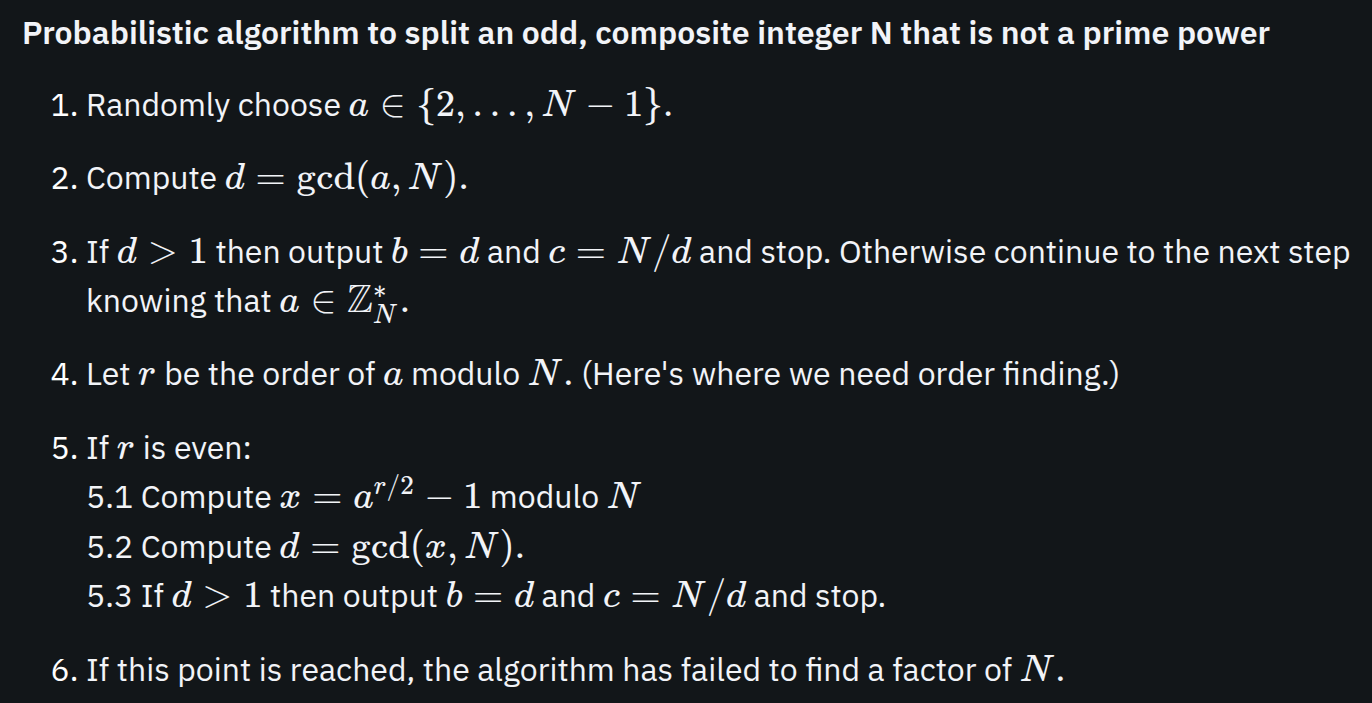

*Figure: from IBM Quantum Learning, [Fundamentals of quantum algorithms — Shor's algorithm](https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms/phase-estimation-and-factoring/shor-algorithm).*

Implement `shor(N, orderfinding)` with these steps. `orderfinding(a, N)` is a function that returns the order of $a$
(or `None` if it failed), so we can plug in different methods. Print **how** the factor was found: by luck in step 3
($\gcd(a, N) > 1$), or from the order $r$ in step 5.

In [7]:
def shor(N, orderfinding):
    """Split a composite N into non-trivial factors using an order-finding callback.
    The odd input is assumed not to be a prime power. Retry failed measurements.
    """
    if N < 4:
        raise ValueError("N must be composite.")
    if N % 2 == 0:
        print(f"Even N: factors 2 and {N // 2}")
        return 2, N // 2
    while True:
        a = random.randint(2, N - 1)
        d = math.gcd(a, N)
        if 1 < d < N:
            print(f"By luck (step 3): gcd({a}, {N}) = {d}")
            return d, N // d

        r = orderfinding(a, N)
        if r is None or r <= 0 or r % 2 == 1:
            continue
        half = mypow(a, r // 2, N)
        if half == 1 or half == N - 1:
            continue
        d = math.gcd(half - 1, N)
        if 1 < d < N:
            print(f"From the order (step 5): a = {a}, r = {r}, gcd({half} - 1, {N}) = {d}")
            return d, N // d

In [8]:
for N in [15, 144227, 85483243]:
    p, q = shor(N, brute_force_order_finding)
    print(f"   {N} = {p} x {q}")

By luck (step 3): gcd(6, 15) = 3
   15 = 3 x 5
From the order (step 5): a = 69077, r = 35844, gcd(82947 - 1, 144227) = 619
   144227 = 619 x 233
From the order (step 5): a = 74684379, r = 4748040, gcd(67421193 - 1, 85483243) = 9811
   85483243 = 9811 x 8713


## A.4 Quantum order finding in five steps

Let $n$ be the number of bits of $N$ and $Q = 2^m \ge N^2$. Quantum order finding uses $m$ **control qubits** and a
**work register**, and $U$ is the gate $U|y\rangle = |a y \bmod N\rangle$:

1. **Superposition + powers.** Hadamards on the control register, then control qubit $j$ applies $U^{2^j}$. Now the
   circuit holds $a^x \bmod N$ for all $x = 0, \dots, Q-1$ at once.
   *This alone gives no speed-up:* measuring now gives just one random $x$.
2. **Interference.** The inverse QFT on the control register turns the period $r$ into sharp peaks at
   $k \approx s\,Q/r$, $s = 0, 1, \dots, r-1$.
3. **Measure** the control register: one number $k$.
4. **Continued fractions** (classical, cheap) turn $k/Q \approx s/r$ into $r$. If $\gcd(s, r) > 1$ the fraction
   reduces and we only get a divisor of $r$; then we try another $k$.

The circuit uses about $n^3$ gates. Brute force needs up to $N \approx 2^n$ steps. More details are [here](https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms/phase-estimation-and-factoring/shor-algorithm).

**Given:** the continued fractions. If $k/Q$ is close to $s/r$, then $s/r$ (in lowest terms) is one of the
*convergents* of $k/Q$, so we test their denominators.

In [9]:
def continued_fraction_convergents(numerator, denominator):
    '''Yield the convergents p/q of numerator/denominator, as (p, q) pairs.'''
    p_prev, p = 0, 1
    q_prev, q = 1, 0
    while denominator != 0:
        t = numerator // denominator
        numerator, denominator = denominator, numerator - t * denominator
        p_prev, p = p, t * p + p_prev
        q_prev, q = q, t * q + q_prev
        yield p, q


def order_from_measurement(k, Q, a, N):
    '''Order r of a mod N from one measured k (k/Q close to s/r), or None.'''
    for _, q in continued_fraction_convergents(k, Q):
        if q >= N:                 # the order is always smaller than N
            break
        if pow(a, q, N) == 1:
            return q
    return None


print(list(continued_fraction_convergents(427, 512)))   # 427/512 is close to 5/6
print(order_from_measurement(427, 512, 2, 21))          # expected: 6

[(0, 1), (1, 1), (5, 6), (211, 253), (427, 512)]
6


### Why the IQFT peaks at $k \approx sQ/r$

**1. After the controlled $U^{2^j}$** (control $\otimes$ work):
$$\frac{1}{\sqrt{Q}}\sum_{x=0}^{Q-1}|x\rangle\,|a^x \bmod N\rangle$$

**2. Measure the work register** $\to y_0 = a^{x_0} \bmod N$, $\;x_0 \in \{0,\dots,r-1\}$. Since $a^{x+r} \equiv a^x \pmod N$, only $x = x_0 + jr$ survive:
$$|\psi\rangle = \frac{1}{\sqrt{M}}\sum_{j=0}^{M-1}|x_0 + jr\rangle, \qquad M = \left\lceil \tfrac{Q-x_0}{r} \right\rceil \approx \frac{Q}{r}$$

**3. Apply the IQFT**, $\;|x\rangle \mapsto \frac{1}{\sqrt{Q}}\sum_{k=0}^{Q-1} e^{-2\pi i\,xk/Q}\,|k\rangle$:
$$\mathrm{IQFT}\,|\psi\rangle = \frac{1}{\sqrt{QM}}\sum_{k=0}^{Q-1}\sum_{j=0}^{M-1} e^{-2\pi i\,(x_0+jr)k/Q}\,|k\rangle$$

**4. Split the exponent**, $\;\frac{(x_0+jr)k}{Q} = \frac{x_0 k}{Q} + j\,\frac{rk}{Q}$:
$$\mathrm{amp}(k) = \underbrace{\frac{e^{-2\pi i\,x_0 k/Q}}{\sqrt{QM}}}_{\text{global phase}}\;\sum_{j=0}^{M-1}\left(e^{-2\pi i\,rk/Q}\right)^{j}$$

**5. Geometric series**, with $\theta = rk/Q$ and $|1-e^{-i\varphi}| = 2|\sin(\varphi/2)|$:
$$\sum_{j=0}^{M-1} e^{-2\pi i\,j\theta} = \frac{1 - e^{-2\pi i\,M\theta}}{1 - e^{-2\pi i\,\theta}}
\quad\Longrightarrow\quad
\left|\sum_{j=0}^{M-1} e^{-2\pi i\,j\theta}\right| = \left|\frac{\sin(\pi M\theta)}{\sin(\pi\theta)}\right|$$

**6. Probability** ($x_0$ drops out):
$$P(k) = |\mathrm{amp}(k)|^2 = \frac{1}{QM}\,\frac{\sin^2(\pi M\,rk/Q)}{\sin^2(\pi\,rk/Q)}$$

**7. Peaks.** If $rk/Q = s \in \mathbb{Z}$, every term is $1$, the sum is $M$:
$$P(k) = \frac{M^2}{QM} = \frac{M}{Q} \approx \frac{1}{r}$$
otherwise the terms cancel and $P(k) \approx 0$. With $0 \le k < Q$:
$$k \approx s\,\frac{Q}{r}, \qquad s = 0, 1, \dots, r-1$$

**8. $Q/r \notin \mathbb{Z}$.** The nearest integer $k$ gets $P(k) \gtrsim \frac{4}{\pi^2 r}$, and
$$\left|k - s\frac{Q}{r}\right| \le \frac{1}{2} \;\Longrightarrow\; \left|\frac{k}{Q} - \frac{s}{r}\right| \le \frac{1}{2Q} \quad (\text{input to continued fractions})$$

*Example* ($N=21,\ a=2,\ r=6,\ Q=512$): peaks at $sQ/r = 0,\ 85.3,\ 170.7,\ 256,\ 341.3,\ 426.7$; the measured $k=427$ is $s=5$.

## A.5 Order finding on a quantum circuit ($N = 21$)

Adapted from NVIDIA's CUDA-Q tutorial [Factoring Integers With Shor's Algorithm](https://nvidia.github.io/cuda-quantum/latest/applications/python/shors.html), with bug fixes.

The work register has 5 qubits and holds $y$, with qubit 0 as the **least significant** bit; it starts in $|1\rangle$.
The circuits for "multiply by $a$ mod 21" are **compiled**: they are only correct on the states that appear when we start
from $|1\rangle$ (for $a = 2$: $1, 2, 4, 8, 16, 11$). Building them needs the answer in advance; that's fine for a demo.
Part B will not need this trick.

In [ ]:
@cudaq.kernel
def quantum_fourier_transform(qubits: cudaq.qview):
    qubit_count = len(qubits)
    for i in range(qubit_count):
        h(qubits[i])
        for j in range(i + 1, qubit_count):
            angle = (2 * np.pi) / (2**(j - i + 1))
            cr1(angle, [qubits[j]], qubits[i])


@cudaq.kernel
def inverse_qft(qubits: cudaq.qview):
    cudaq.adjoint(quantum_fourier_transform, qubits)

In [ ]:
@cudaq.kernel
def modular_mult_2_21(work: cudaq.qview):
    '''Multiply by 2 mod 21 (compiled: correct on the states 1, 2, 4, 8, 16, 11).'''
    swap(work[3], work[4])          # rotate the bits: 1 -> 2 -> 4 -> 8 -> 16 -> 1, and 11 -> 22
    swap(work[2], work[3])
    swap(work[1], work[2])
    swap(work[0], work[1])
    x.ctrl(work[0], work[1])        # fix-up 1 -> 11 (so that 16 -> 11) ...
    x.ctrl(work[0], work[3])
    x.ctrl([work[4], work[2]], work[1])   # ... and 22 -> 1 (so that 11 -> 1)
    x.ctrl([work[4], work[2]], work[0])
    x.ctrl([work[4], work[0]], work[2])
    x(work[3])
    x.ctrl([work[0], work[3]], work[4])
    x(work[3])


@cudaq.kernel
def modular_mult_5_21(work: cudaq.qview):
    '''Multiply by 5 mod 21 (compiled: correct on the states 1, 5, 4, 20, 16, 17).
    Based on https://physlab.org/wp-content/uploads/2023/05/Shor_s_Algorithm_23100113_Fin.pdf'''
    x(work[0])
    x(work[2])
    x(work[4])
    swap(work[0], work[4])
    swap(work[0], work[2])


@cudaq.kernel
def modular_exp_21(a: int, exponent: cudaq.qview, work: cudaq.qview):
    '''|x>|1> -> |x>|a^x mod 21> for a = 2 or 5: control qubit j applies U 2^j times.'''
    x(work[0])
    for j in range(len(exponent)):
        for _ in range(2**j):
            if a == 2:
                cudaq.control(modular_mult_2_21, exponent[j], work)
            else:
                cudaq.control(modular_mult_5_21, exponent[j], work)


@cudaq.kernel
def demonstrate_mod_exponentiation(a: int, iterations: int):
    qubits = cudaq.qvector(5)
    x(qubits[0])                    # y = 1
    for _ in range(iterations):
        if a == 2:
            modular_mult_2_21(qubits)
        else:
            modular_mult_5_21(qubits)


for a in [2, 5]:
    got = [int(cudaq.sample(demonstrate_mod_exponentiation, a, i, shots_count=50).most_probable()[::-1], 2)
           for i in range(7)]
    print(f"a = {a}: circuit {got}, a^x mod 21 = {[pow(a, i, 21) for i in range(7)]}")

`phase_kernel` is steps 1–3. `cudaq.sample` returns the bit string with control qubit 0 first. With this QFT (no final
swaps) that string, read as an ordinary binary number, **is** $k$: `k = int(bits, 2)`.

In [ ]:
@cudaq.kernel
def phase_kernel(control_register_size: int, a: int):
    qubits = cudaq.qvector(control_register_size + 5)
    control_register = qubits[0:control_register_size]
    work_register = qubits[control_register_size:control_register_size + 5]
    h(control_register)
    modular_exp_21(a, control_register, work_register)
    inverse_qft(control_register)
    mz(control_register)


a, N, nc, shots = 2, 21, 9, 15000              # Q = 2^9 = 512 >= 21^2
results = cudaq.sample(phase_kernel, nc, a, shots_count=shots)
Q, r = 2 ** nc, brute_force_order_finding(a, N)   # r only to draw where the peaks should be
items = list(results.items())
k_meas = np.array([int(bits, 2) for bits, _ in items])
p_meas = np.array([count for _, count in items]) / shots

fig, ax = plt.subplots(figsize=(10, 3))
for s in range(r):
    ax.axvline(s * Q / r, color="#52514e", linestyle="--", linewidth=1, alpha=0.5)
ax.vlines(k_meas, 0, p_meas, color="#2a78d6", linewidth=1.5)
ax.set_xlim(-Q / 100, Q)
ax.set_xlabel("measured k")
ax.set_ylabel("fraction of shots")
ax.set_title(f"Order finding for a = {a}, N = {N}: peaks at k = s·Q/r with r = {r}")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [ ]:
def find_order_quantum(a, N=21, nc=9, shots=2000):
    '''Quantum order finding with the circuits above (a = 2 or 5, N = 21).'''
    results = cudaq.sample(phase_kernel, nc, a, shots_count=shots)
    for bits, count in sorted(results.items(), key=lambda kv: kv[1], reverse=True):   # most frequent first
        k = int(bits, 2)
        if k == 0:
            continue
        r = order_from_measurement(k, 2 ** nc, a, N)
        print(f"  measured k = {k:3d} ({count} shots): continued fractions of {k}/{2 ** nc} give r = {r}")
        if r is not None:
            return r
    return None


def test_order(a, r, N):
    '''Step 5: two non-trivial factors of N from the order r of a, or (0, 0).'''
    if r is None or r % 2 == 1:
        print(f"  r = {r}: no factor from this a")
        return 0, 0
    half = pow(a, r // 2, N)                 # a^(r/2) mod N
    if half == N - 1:
        print(f"  {a}^{r // 2} = -1 (mod {N}): no factor from this a")
        return 0, 0
    for factor in (math.gcd(half - 1, N), math.gcd(half + 1, N)):
        if 1 < factor < N:
            return factor, N // factor
    return 0, 0


r = find_order_quantum(2)
print("a = 2: order", r, "-> factors of 21:", test_order(2, r, 21))

## TODO A4: An unlucky $a$

Run the next cell. The quantum circuit finds the correct order of $a = 5$. Why can't we use it to factor 21?

#### ANS:

The correct order is $r=6$, but
$$5^{r/2}=5^3=125\equiv20\equiv-1\pmod{21}.$$
Therefore
$$\gcd(5^3-1,21)=\gcd(124,21)=1,\qquad
\gcd(5^3+1,21)=\gcd(126,21)=21.$$
Both factors are trivial. An even order alone is insufficient: we need
$a^{r/2}\not\equiv\pm1\pmod N$. The circuit succeeds at finding the order;
the classical factoring step fails for this choice of $a$, so Shor's algorithm
must choose another base. For example, $a=2$ also has order 6, but
$2^3\equiv8\pmod{21}$, giving $\gcd(8-1,21)=7$ and $\gcd(8+1,21)=3$.

In [ ]:
r = find_order_quantum(5)
print("a = 5: order", r, "-> factors of 21:", test_order(5, r, 21))

# Part B — When does the scrambled cat come back?

In Part A, order finding found the smallest $r$ with $a^r \equiv 1 \pmod N$. In Part B you use the same idea on a picture.

**Arnold's cat map** moves every pixel of an $N \times N$ image to a new place. After one step the cat is stretched,
after a few steps it is noise, and after **exactly $\Pi(N)$ steps the cat is back**. The number $\Pi(N)$ is an
order, and you will find it with your own phase-estimation circuit. The picture itself never enters the quantum
computer: the circuit only moves **pixel coordinates**.

| step | what you build |
|---|---|
| B.1 | look at the cat map |
| B.2 | the period is an order: brute force, and the orbit of each pixel |
| B.3 | repeated squaring for $2 \times 2$ matrices |
| B.4 | one cat step as a quantum circuit: adding in the Fourier basis |
| B.5 | phase estimation of the cat map |
| B.6 | from the measured $k$ to the period; big pictures |
| B.7, B.8, B.9 | the cost, where the speed-up really is, and challenges |

Arnold drew the cat in V. I. Arnold and A. Avez, *Ergodic Problems of Classical Mechanics* (1968).
The picture is "Chelsea the cat" from scikit-image (CC0).

In [ ]:
# !unzip -q -o mylib.zip                     # Colab only: unpack the helper library
from math import lcm

import sys
from pathlib import Path
lab_paths = [Path.cwd(), Path("Lab/Arnold_Cat_Map-Shor_student_6af4e1b3ea324/Shor_Lab_student")]
lab_dir = next((p.resolve() for p in lab_paths if (p / "mylib").is_dir()), None)
if lab_dir is None:
    raise FileNotFoundError("Run from the notebook folder or repository root, with mylib unpacked.")
if str(lab_dir) not in sys.path:
    sys.path.insert(0, str(lab_dir))

import mylib
from mylib import catmap, samplers, checks
from mylib.catmap import M                   # the cat map M = [[2, 1], [1, 1]], stored as (2, 1, 1, 1)

mylib.info()

## B.1 The cat map in one minute

Number the pixels by column $x$ and row $y$, both from $0$ to $N-1$. One step moves the pixel at $(x, y)$ to
$$
\begin{pmatrix} x' \\ y' \end{pmatrix} = M \begin{pmatrix} x \\ y \end{pmatrix} \bmod N,
\qquad M = \begin{pmatrix} 2 & 1 \\ 1 & 1 \end{pmatrix},
\qquad\text{that is}\quad (x', y') = (2x + y,\ x + y) \bmod N .
$$
$\det M = 1$, so $M$ has an inverse modulo $N$: two pixels never land on the same place. The map only **shuffles**
the pixels and loses nothing. There are only finitely many shuffles, so after enough steps the image must come back.

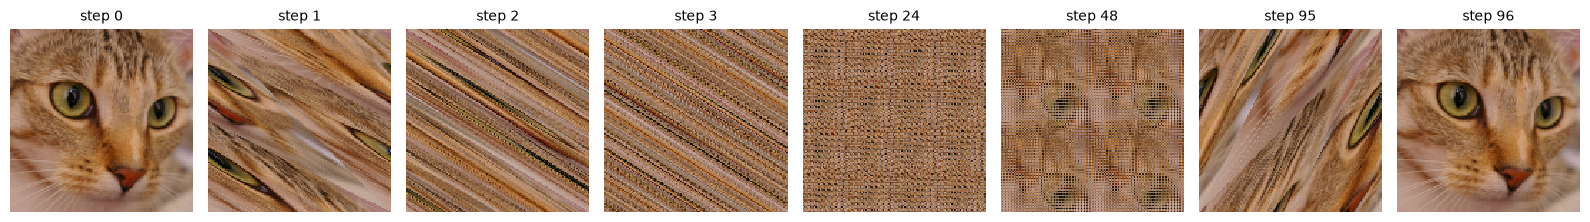

In [16]:
cat = catmap.load_cat(128)                   # a 128 x 128 photo
catmap.show_frames(cat, [0, 1, 2, 3, 24, 48, 95, 96])

For $128 \times 128$ the cat comes back after 96 steps. Step 95 is one step **before** that, and step 48 shows four
small ghost cats (B.6 explains them). The question of Part B: **how can we find 96 without watching every step?**

## B.2 The period is an order

After $k$ steps a pixel $p$ is at $M^k p \bmod N$. The whole image is back when $M^k \equiv I \pmod N$. So
$$
\Pi(N) = \text{the smallest } k \ge 1 \text{ with } M^k \equiv I \pmod N = \text{the order of } M \text{ modulo } N .
$$
That is Part A's order, with a $2 \times 2$ matrix instead of a number.

### TODO B1: the period by brute force

Multiply by $M$ until you get the identity. Use `catmap.matmul(A, B, N)` ($A B \bmod N$) and `catmap.identity(N)`.

In [17]:
def cat_period_classical(N):
    """Smallest k >= 1 with M^k = I (mod N)."""
    if N < 1:
        raise ValueError("N must be positive.")
    P, k = tuple(v % N for v in M), 1
    while P != catmap.identity(N):
        P = catmap.matmul(P, M, N)
        k += 1
    return k

In [18]:
checks.check_cat_period_classical(cat_period_classical)
for N in [16, 32, 124, 128, 150, 256]:
    print(f"{N:3d} x {N:3d} image: the cat comes back after {cat_period_classical(N)} steps")

✅ cat_period_classical is right for N = [2, 3, 4, 5, 8, 10, 16, 32, 124, 128, 150]
 16 x  16 image: the cat comes back after 12 steps
 32 x  32 image: the cat comes back after 24 steps
124 x 124 image: the cat comes back after 15 steps
128 x 128 image: the cat comes back after 96 steps
150 x 150 image: the cat comes back after 300 steps
256 x 256 image: the cat comes back after 192 steps


### Every pixel has its own orbit

Each pixel comes back after its own number of steps, its **orbit length**. The image is back when **all** pixels are
back, so $\Pi(N)$ is the lcm of all orbit lengths. Two pixels are enough: $M^k (1,0)$ is the first column of $M^k$ and
$M^k (0,1)$ is the second column. So $M^k \equiv I$ exactly when both pixels are back:
$$
\Pi(N) = \operatorname{lcm}\big(r_{(1,0)},\ r_{(0,1)}\big),
$$
where $r_p$ is the orbit length of $p$. The quantum computer will find these two orbit lengths.

orbit length: number of pixels -> {1: 1, 3: 15, 6: 48, 12: 192, 24: 768, 48: 3072}
lcm of all orbit lengths: 48    cat_period_classical: 48
orbit of (1, 0): 48    orbit of (0, 1): 48


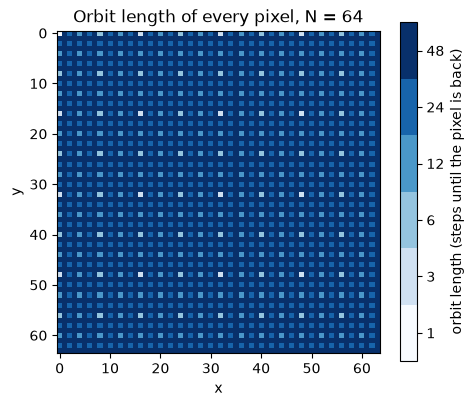

In [19]:
N = 64
orbits = catmap.orbit_lengths(N)
values = sorted(set(int(v) for v in orbits.ravel()))
print("orbit length: number of pixels ->", {v: int((orbits == v).sum()) for v in values})
print("lcm of all orbit lengths:", lcm(*values), "   cat_period_classical:", cat_period_classical(N))
print("orbit of (1, 0):", catmap.orbit_length((1, 0), N), "   orbit of (0, 1):", catmap.orbit_length((0, 1), N))

fig, ax = plt.subplots(figsize=(5.2, 4.4))
level = np.searchsorted(values, orbits)              # 0, 1, 2, ... for the sorted orbit lengths
im = ax.imshow(level, cmap=plt.get_cmap("Blues", len(values)), vmin=-0.5, vmax=len(values) - 0.5,
               interpolation="nearest")
cb = fig.colorbar(im, ticks=range(len(values)))
cb.set_ticklabels([str(v) for v in values])
cb.set_label("orbit length (steps until the pixel is back)")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"Orbit length of every pixel, N = {N}")
plt.show()

Most pixels need the full period. The lighter squares are pixels whose coordinates are both even: they move like the
pixels of a picture half as big, so they come back sooner.

## B.3 Repeated squaring for matrices

In Part A, control qubit $j$ multiplied by $a^{2^j} \bmod N$, and `mypow` computed such powers by squaring.
The cat-map circuit needs $M^{2^j} \bmod N$ in the same way.

### TODO B2: `matpow`

Write `matpow(A, k, N)` $= A^k \bmod N$ for a $2 \times 2$ matrix $A$, exactly like `mypow`, with `catmap.matmul`
instead of `*` and `catmap.identity(N)` instead of 1.

In [20]:
def matpow(A, k, N):
    """A^k mod N by repeated squaring."""
    if k < 0 or N <= 0:
        raise ValueError("Require a non-negative exponent and a positive modulus.")
    result = catmap.identity(N)
    base = tuple(int(v) % N for v in A)
    while k > 0:
        if k % 2 == 1:
            result = catmap.matmul(result, base, N)
        base = catmap.matmul(base, base, N)
        k //= 2
    return result

In [21]:
checks.check_matpow(matpow)
print("M^96 mod 128 =", matpow(M, 96, 128), " (the identity: the cat is back)")
print("M^48 mod 128 =", matpow(M, 48, 128), " (remember step 48)")

✅ matpow is right on 305 cases (exponents up to 10^15)
M^96 mod 128 = (1, 0, 0, 1)  (the identity: the cat is back)
M^48 mod 128 = (65, 0, 0, 65)  (remember step 48)


## B.4 One cat step as a quantum circuit

The work register is two registers `px` and `py` of $n$ qubits each, for $N = 2^n$, holding the pixel $(x, y)$
(qubit 0 = least significant bit). One cat step is two **shears**:
$$
y \leftarrow y + x, \qquad\text{then}\qquad x \leftarrow x + y \qquad (\bmod N),
$$
which gives $(x + (x + y),\ x + y) = (2x + y,\ x + y)$. A shear is an **addition**, and an addition can be undone
(subtract again), so it is a valid quantum gate.

### Adding in the Fourier basis (Draper, 2000)

`qft_lsb` (given) is a QFT without the final swaps. Afterwards **qubit $a$ of the register holds the phase
$2\pi x / 2^{a+1}$**: it stores $x$ as an angle, with $a + 1$ bits of precision.

* To add a number $c$, rotate qubit $a$ by $2\pi c / 2^{a+1}$ (an `r1` gate). Now it holds $2\pi (x + c)/2^{a+1}$.
  The "mod $2^n$" is free: angles wrap around.
* We add $c = k \cdot y = \sum_j k\, 2^j\, y_j$. So for every bit $y_j$, rotate qubit $a$ by
  $2\pi\, k\, 2^j / 2^{a+1}$, **controlled by** $y_j$: `r1.ctrl(angle, source[j], target[a])`.
  For $j > a$ the angle is a multiple of $2\pi$, so we skip it.
* An inverse QFT turns the angles back into the number $x + k y$.

In [ ]:
@cudaq.kernel
def qft_lsb(q: cudaq.qview):
    '''QFT without the final swaps, for a register with q[0] = least significant bit.
    Afterwards qubit a holds the phase 2*pi*x / 2^(a+1).'''
    n = q.size()
    for i in range(n):
        a = n - 1 - i                    # from the most significant qubit down
        h(q[a])
        for b in range(a):
            r1.ctrl(2.0 * np.pi / 2**(a - b + 1), q[b], q[a])

### TODO B3: the rotations

`fourier_add` does the rotations, on a target that is already in the Fourier basis. Fill in the rotation of qubit `a`
of the target, controlled by bit `j` of the source. `shear` (given) is then: `qft_lsb`, `fourier_add`, inverse `qft_lsb`.

**Hint: the angle `theta` $= \theta_{a,j}$**

1. After `qft_lsb`, target qubit $a$ is $\tfrac{1}{\sqrt 2}\big(|0\rangle + e^{i\varphi_a}|1\rangle\big)$ with $\varphi_a = \dfrac{2\pi\,x}{2^{a+1}}$.
2. $R_1(\theta) = \mathrm{diag}(1, e^{i\theta})$ shifts that phase: $\;\varphi_a \to \varphi_a + \theta$.
3. Goal: $\varphi_a \to \dfrac{2\pi\,(x + k\,y)}{2^{a+1}}$. Write $y = \sum_j y_j\,2^j$:
$$
\frac{2\pi\,(x + k\,y)}{2^{a+1}} = \varphi_a + \sum_{j} y_j\,\theta_{a,j}, \qquad \theta_{a,j} = \frac{2\pi\,k\,2^j}{2^{a+1}}
$$
4. "Add $\theta_{a,j}$ only if $y_j = 1$" is exactly `r1.ctrl(theta, source[j], target[a])`.
5. $j > a$: $\;\theta_{a,j} = 2\pi\,k\,2^{\,j-a-1} \equiv 0 \pmod{2\pi}$, hence `range(a + 1)`. Optional: use $(k\,2^j) \bmod 2^{a+1}$
   instead of $k\,2^j$ (same gate, smaller angle).

*Check* ($k = 1$): $\theta_{a,j} = 2\pi / 2^{a-j+1}$; for $j < a$ these are the `r1` angles of `qft_lsb`.

| $\theta_{a,j}$, $k = 1$ | $j = 0$ | $j = 1$ | $j = 2$ |
|:-:|:-:|:-:|:-:|
| $a = 0$ | $\pi$ | | |
| $a = 1$ | $\pi/2$ | $\pi$ | |
| $a = 2$ | $\pi/4$ | $\pi/2$ | $\pi$ |

In [ ]:
@cudaq.kernel
def fourier_add(target: cudaq.qview, source: cudaq.qview, k: int):
    '''Add k * source to a target that is in the Fourier basis (after qft_lsb).'''
    n = target.size()
    for a in range(n):
        for j in range(a + 1):
            theta = 2.0 * np.pi * ((k * 2**j) % 2**(a + 1)) / 2**(a + 1)
            r1.ctrl(theta, source[j], target[a])


@cudaq.kernel
def shear(target: cudaq.qview, source: cudaq.qview, k: int):
    '''target <- target + k * source (mod 2^n), for a classical number k.'''
    qft_lsb(target)
    fourier_add(target, source, k)
    cudaq.adjoint(qft_lsb, target)


@cudaq.kernel
def cat_step(px: cudaq.qview, py: cudaq.qview):
    '''One step of the cat map: (x, y) -> (2x + y, x + y) mod 2^n.'''
    shear(py, px, 1)                     # y <- y + x
    shear(px, py, 1)                     # x <- x + y   (y is already x + y)

In [ ]:
@cudaq.kernel
def load_pixel(px: cudaq.qview, py: cudaq.qview, x0: int, y0: int):
    '''Prepare |x0>|y0> (qubit 0 = least significant bit).'''
    for i in range(px.size()):
        if int(x0 / 2**i) % 2 == 1:
            x(px[i])
        if int(y0 / 2**i) % 2 == 1:
            x(py[i])


@cudaq.kernel
def shear_test(n: int, x0: int, y0: int, k: int):
    px = cudaq.qvector(n)
    py = cudaq.qvector(n)
    load_pixel(px, py, x0, y0)
    shear(px, py, k)
    mz(px)
    mz(py)


def read_pixel(bits, n):
    '''Bit string of px then py (qubit 0 first) -> (x, y).'''
    return int(bits[:n][::-1], 2), int(bits[n:2 * n][::-1], 2)


def run_shear(n, x0, y0, k):
    return read_pixel(cudaq.sample(shear_test, n, x0, y0, k, shots_count=20).most_probable(), n)


checks.check_shear(run_shear)

Now follow the pixel $(1, 0)$ of a $32 \times 32$ image through the cat map, on the quantum circuit:

In [ ]:
@cudaq.kernel
def cat_walk(n: int, x0: int, y0: int, steps: int):
    px = cudaq.qvector(n)
    py = cudaq.qvector(n)
    load_pixel(px, py, x0, y0)
    for _ in range(steps):
        cat_step(px, py)
    mz(px)
    mz(py)


n, N = 5, 32
path = [read_pixel(cudaq.sample(cat_walk, n, 1, 0, s, shots_count=10).most_probable(), n) for s in range(25)]
classical = [(1, 0)]
for _ in range(24):
    classical.append(catmap.apply(M, classical[-1], N))
print("the pixel (1, 0) on the circuit:", path)
print("same as the classical map:", path == classical, "  back home after", path.index((1, 0), 1), "steps")

## B.5 Phase estimation of the cat map

This is Part A's circuit with a new $U$: $\;U|x, y\rangle = |M(x, y) \bmod N\rangle$. Start in the pixel $p = (1, 0)$.
Its orbit has length $r$, so $U^r p = p$, and phase estimation finds peaks at $k \approx s\,Q/r$.

**The powers.** Control qubit $j$ must apply $U^{2^j}$, which is the matrix $M^{2^j} \bmod N$. Your `matpow` computes
it classically and cheaply, exactly like $a^{2^j} \bmod N$ in Shor's algorithm. We do **not** repeat the cat step
$2^j$ times.

**Three shears.** Every matrix with determinant 1 is a product of shears. If $c$ is odd (so it has an inverse mod $2^n$),
$$
\begin{pmatrix} a & b \\ c & d \end{pmatrix}
= \begin{pmatrix} 1 & t \\ 0 & 1 \end{pmatrix}
  \begin{pmatrix} 1 & 0 \\ c & 1 \end{pmatrix}
  \begin{pmatrix} 1 & s \\ 0 & 1 \end{pmatrix},
\qquad s = \frac{d - 1}{c},\quad t = \frac{a - 1}{c} \pmod N,
$$
so $U^{2^j}$ is: $x \leftarrow x + s y$, then $y \leftarrow y + c x$, then $x \leftarrow x + t y$.
`catmap.shears(A, N)` does this. For the cat map, $c$ is the Fibonacci number $F_{2^{j+1}}$, which is always odd.

**The control.** `controlled_shear` is your shear with `cudaq.control` on `fourier_add` only. The QFT and its
inverse need no control: without the rotations they cancel.

**How many control qubits?** Dyson and Falk (1992) proved that the period is at most $3N$. With $Q = 2^m > (3N)^2$,
continued fractions always find $s/r$ from the closest $k$ (as in Part A, where $Q \ge N^2$).

In [ ]:
@cudaq.kernel
def controlled_shear(c: cudaq.qubit, target: cudaq.qview, source: cudaq.qview, k: int):
    '''shear(target, source, k) if the qubit c is 1.'''
    qft_lsb(target)
    cudaq.control(fourier_add, c, target, source, k)     # only the rotations need the control
    cudaq.adjoint(qft_lsb, target)


def power_shears(N, m):
    '''The shears of U^(2^j) = M^(2^j) mod N for j = 0 .. m-1, as three lists for the kernel:
    shear s (off[j] <= s < off[j+1]) belongs to U^(2^j);
    tg[s] = 0 means x <- x + ks[s] * y,  tg[s] = 1 means y <- y + ks[s] * x.'''
    tg, ks, off = [], [], [0]
    for j in range(m):
        for target, k in catmap.shears(matpow(M, 2**j, N), N):     # your matpow
            tg.append(target)
            ks.append(k)
        off.append(len(tg))
    return tg, ks, off


N = 32
m = samplers.control_qubits(N)
tg, ks, off = power_shears(N, m)
print(f"N = {N}: m = {m} control qubits, Q = 2^{m} = {2**m} > (3N)^2 = {9 * N * N}")
for j in range(4):
    sh = [("x += %d*y" if t == 0 else "y += %d*x") % k for t, k in zip(tg[off[j]:off[j + 1]], ks[off[j]:off[j + 1]])]
    print(f"  U^{2**j:<2d} = M^{2**j} mod {N} = {matpow(M, 2**j, N)}:  " + ",  then ".join(sh))

### TODO B4: the phase-estimation kernel

Write `cat_qpe` like Part A's `phase_kernel`:
1. prepare the start pixel with `load_pixel`, and put the control register in superposition;
2. for every control qubit $j$, apply the shears `s` = `off[j]` to `off[j+1] - 1` with `controlled_shear`, controlled by `ctrl[j]`
   (`tg[s] == 0`: target `px`, source `py`; `tg[s] == 1`: target `py`, source `px`);
3. apply Part A's `inverse_qft` to the control register.

In [ ]:
@cudaq.kernel
def cat_qpe(n: int, m: int, x0: int, y0: int, tg: list[int], ks: list[int], off: list[int]):
    """Phase estimation of the cat map from (x0, y0); measure the control qubits."""
    ctrl = cudaq.qvector(m)
    px = cudaq.qvector(n)
    py = cudaq.qvector(n)
    load_pixel(px, py, x0, y0)
    h(ctrl)
    for j in range(m):
        for s in range(off[j], off[j + 1]):
            if tg[s] == 0:
                controlled_shear(ctrl[j], px, py, ks[s])
            else:
                controlled_shear(ctrl[j], py, px, ks[s])
    inverse_qft(ctrl)
    mz(ctrl)

In [ ]:
circuit = samplers.CircuitSampler(cat_qpe)
p = (1, 0)
counts = circuit.counts(N, p, tg, ks, off, m, shots=2000)
print(f"{m + 2 * 5} qubits, {catmap.qpe_gate_count(5, m)} gates, {circuit.seconds:.1f} s")
checks.check_cat_qpe(counts, N, p)

Q = 2 ** m
r = catmap.orbit_length(p, N)                     # only to draw and explain the peaks
k_meas = np.array([int(bits, 2) for bits in counts])
p_meas = np.array(list(counts.values())) / sum(counts.values())

fig, ax = plt.subplots(figsize=(10, 3))
for s in range(r):
    ax.axvline(s * Q / r, color="#52514e", linestyle="--", linewidth=1, alpha=0.4)
ax.vlines(k_meas, 0, p_meas, color="#2a78d6", linewidth=1.5)
ax.set_xlim(-Q / 100, Q)
ax.set_xlabel("measured k")
ax.set_ylabel("fraction of shots")
ax.set_title(f"Phase estimation of the cat map, N = {N}, start pixel {p}: peaks at k = s·Q/r with r = {r}")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

print("the most frequent outcomes:")
for bits, c in sorted(counts.items(), key=lambda kv: kv[1], reverse=True)[:10]:
    k = int(bits, 2)
    s = round(k * r / Q) % r
    print(f"  k = {k:5d} ({c:3d} shots): k/Q is close to {s}/{r} = {s // math.gcd(s, r)}/{r // math.gcd(s, r)}")

**Tall but useless.** The tallest peaks are at $s = 0, 3, 6, \dots$. There $s/24$ reduces to a fraction with
denominator 8 or less, which divides $Q$. So the peak sits **exactly** on one value of $k$ and gets all its probability.
But its denominator is only a divisor of 24. The useful peaks ($s$ with $\gcd(s, 24) = 1$) fall between two values of
$k$, so they are lower and wider. So we must sometimes look past the tallest peaks.

## B.6 From $k$ to the period

### TODO B5: `orbit_from_measurement`

Copy Part A's `order_from_measurement` and change two things: the test $a^q \equiv 1 \pmod N$ becomes
$M^q p \equiv p \pmod N$ (use your `matpow` and `catmap.apply(A, p, N)`), and the orbit is at most $3N$ long (not $N$).

In [29]:
def orbit_from_measurement(k, Q, p, N):
    """Recover the orbit length from a measured k/Q, or None if it is unhelpful."""
    if N < 1 or Q <= 0 or not 0 <= k < Q:
        raise ValueError("Require N >= 1, Q > 0, and 0 <= k < Q.")
    p = tuple(int(v) % N for v in p)
    for _, q in continued_fraction_convergents(k, Q):
        if q > 3 * N:
            break
        if catmap.apply(matpow(M, q, N), p, N) == p:
            return q
    return None

In [30]:
checks.check_orbit_from_measurement(orbit_from_measurement)

✅ orbit_from_measurement finds r when gcd(s, r) = 1, and returns None otherwise


### the period from the circuit

For both pixels $(1, 0)$ and $(0, 1)$: run the sampler, try the outcomes from the most to the least frequent
(skip $k = 0$) until `orbit_from_measurement` finds the orbit length. Return the lcm of the two orbit lengths.
`sampler.counts(N, p, tg, ks, off, m, shots)` returns `{bit string: count}` like `cudaq.sample`.

In [31]:
def cat_period_quantum(N, sampler, shots=2000):
    '''Period of the cat map on an N x N image (N = 2^n), by phase estimation.'''
    if N < 2 or N & (N - 1):
        raise ValueError("The quantum circuit requires N = 2^n with n >= 1.")
    if shots < 1:
        raise ValueError("shots must be positive.")
    m = samplers.control_qubits(N)
    tg, ks, off = power_shears(N, m)
    orbits = []
    for p in [(1, 0), (0, 1)]:
        counts = sampler.counts(N, p, tg, ks, off, m, shots)
        r = None
        for bits, _ in sorted(counts.items(), key=lambda kv: kv[1], reverse=True):   # most frequent first
            k = int(bits, 2)
            if k != 0:
                r = orbit_from_measurement(k, 2 ** m, p, N)
            if r is not None:
                break
        if r is None:
            return None
        orbits.append(r)
    return lcm(*orbits)

In [32]:
checks.check_cat_period_quantum(cat_period_quantum)

✅ cat_period_quantum is right for N = 16, 32, 64, 128, 256 (IdealSampler)


Now on the real circuit, every gate simulated. The $64 \times 64$ image needs 28 qubits (2 GB of GPU memory).

In [ ]:
RUN_64 = True               # 64 x 64: 28 qubits, about 15 s; set to False to skip

for N in [16, 32] + ([64] if RUN_64 else []):
    circuit = samplers.CircuitSampler(cat_qpe)
    period = cat_period_quantum(N, circuit)
    n, m = N.bit_length() - 1, samplers.control_qubits(N)
    print(f"{N:2d} x {N:2d}: {m + 2 * n} qubits, period from the circuit = {period}, classical = "
          f"{cat_period_classical(N)}   ({circuit.calls} circuit runs, {circuit.seconds:.1f} s)")

### Bigger pictures

A $256 \times 256$ image needs $m = 20$ control qubits and 36 qubits in all: too many to simulate.
`samplers.IdealSampler` samples the exact output distribution of the same noiseless circuit (see `mylib/samplers.py`).
To imitate the circuit it uses the classical orbit length, but your code only sees the measured bit strings.

256 x 256: period 192 (from IdealSampler), classical 192


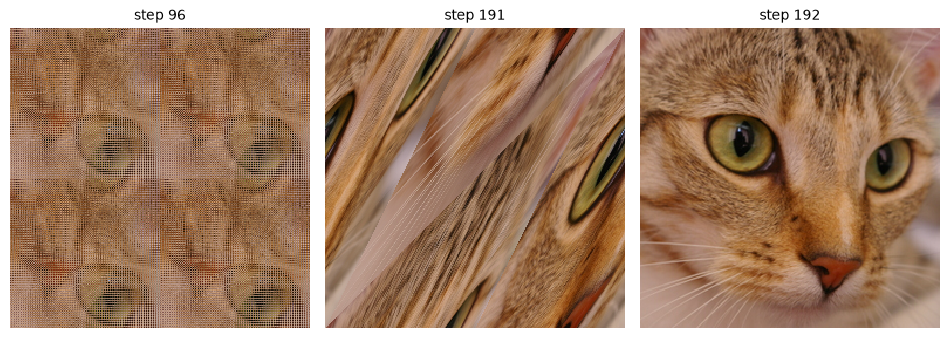

In [34]:
N = 256
period = cat_period_quantum(N, samplers.IdealSampler(seed=0))
print(f"{N} x {N}: period {period} (from IdealSampler), classical {cat_period_classical(N)}")
catmap.show_frames(catmap.load_cat(N), [period // 2, period - 1, period], size=3.2)

**The ghost cats.** For $N = 2^n$ (from $N = 8$ on), $M^{\Pi/2} \equiv (1 + N/2)\, I \pmod N$; you saw
`M^48 mod 128 = (65, 0, 0, 65)` in B.3. So at half the period, every **even** coordinate stays and every **odd** one
moves by half the picture. The four quarters of the cat get mixed into each other, and you see ghost copies.

## B.7 How does the cost grow?

In [35]:
print("  n      N   qubits   gates   brute-force steps (= the period)")
for n in range(3, 11):
    N = 2 ** n
    m = samplers.control_qubits(N)
    print(f"{n:3d} {N:6d} {m + 2 * n:6d} {catmap.qpe_gate_count(n, m):9d} {cat_period_classical(N):10d}")

  n      N   qubits   gates   brute-force steps (= the period)
  3      8     16       605          6
  4     16     20      1170         12
  5     32     24      2009         24
  6     64     28      3176         48
  7    128     32      4725         96
  8    256     36      6710        192
  9    512     40      9185        384
 10   1024     44     12204        768


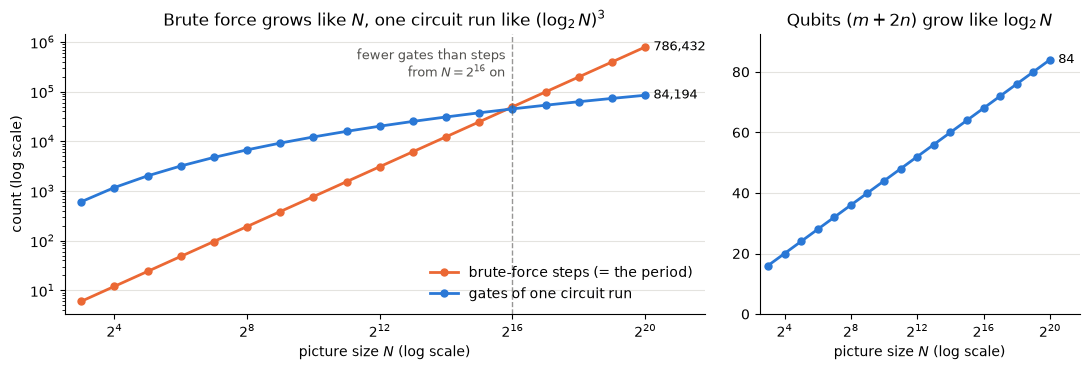

In [36]:
# The table above on a log scale, continued up to N = 2^20 (brute force there: 786,432 steps, about a second)
ns = list(range(3, 21))                          # plain ints: control_qubits uses int.bit_length
qubits = [samplers.control_qubits(2 ** n) + 2 * n for n in ns]
gates = [catmap.qpe_gate_count(n, samplers.control_qubits(2 ** n)) for n in ns]
steps = [cat_period_classical(2 ** n) for n in ns]
cross = next(n for n, g, s in zip(ns, gates, steps) if g < s)   # first n: one circuit run has fewer gates than brute force has steps

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [2, 1]})
ax.semilogy(ns, steps, "o-", color="#eb6834", lw=2, ms=5, label="brute-force steps (= the period)")
ax.semilogy(ns, gates, "o-", color="#2a78d6", lw=2, ms=5, label="gates of one circuit run")
ax.axvline(cross, color="#52514e", ls="--", lw=1, alpha=0.6)
ax.text(cross - 0.2, max(steps), f"fewer gates than steps\nfrom $N = 2^{{{cross}}}$ on", ha="right", va="top",
        color="#52514e", fontsize=9)
for y in (steps, gates):
    ax.annotate(f"{y[-1]:,}", (ns[-1], y[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9)
ax.set_title(r"Brute force grows like $N$, one circuit run like $(\log_2 N)^3$")
ax.set_ylabel("count (log scale)")
ax.legend(frameon=False, loc="lower right")

ax2.plot(ns, qubits, "o-", color="#2a78d6", lw=2, ms=5)
ax2.annotate(f"{qubits[-1]}", (ns[-1], qubits[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9)
ax2.set_ylim(0, max(qubits) * 1.1)
ax2.set_title(r"Qubits ($m + 2n$) grow like $\log_2 N$")

for a in (ax, ax2):
    a.set_xticks(ns[1::4])
    a.set_xticklabels([f"$2^{{{n}}}$" for n in ns[1::4]])
    a.set_xlim(ns[0] - 0.5, ns[-1] + 1.8)
    a.set_xlabel("picture size $N$ (log scale)")
    a.grid(axis="y", color="#e4e3df", lw=0.8)
    a.set_axisbelow(True)
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

### Validation and execution note

The saved outputs are from the classical and `IdealSampler` cells. All supplied
classical checks passed, including 305 matrix-power cases and period recovery
for image sizes 16, 32, 64, 128, and 256. Modular exponentiation also passed
1,003 random and edge cases, and the Shor retry and factor-extraction branches
were checked.

CUDA-Q is not installed in the local environment, so the CUDA-Q execution cells
are left unexecuted. An independent NumPy gate simulator verified all 46 supplied
Fourier-addition cases, both modular-multiplier orbits, Part A phase estimation,
and the complete cat-map QPE distributions for N = 4 and N = 8 (both basis
pixels at N = 8). This checks the gate mathematics; CUDA-Q compilation and the
larger GPU runs still require the CUDA-Q environment specified at the top.
